# 05 · Evaluación final (Fase 5)
**Esta es la única notebook que toca el test oficial (1004 imágenes, 110 defectuosas).** Protocolo D-045, aprobado:
- Modelos: baseline (ResNet18 + logística), CNN (semillas 42, 1, 2) y autoencoder `b2` (semillas 42, 1, 2). Sampler y scratch no entran (fueron controles).
- Cada modelo se evalúa con **su propio umbral de validación** (el que maximizó F2 en val). Nada se reajusta con el test.
- Se reporta media ± desvío entre semillas, IC bootstrap, curvas, la sensibilidad al umbral (solo informativa), el bootstrap pareado y el análisis de errores con Grad-CAM de la CNN de **semilla 42** (regla fijada de antemano).
- Si el test sale peor que la validación, se reporta tal cual (sesgo de selección esperado).

**Antes de correr:** todo commiteado y pusheado (queda como registro de qué estaba fijado antes de ver el test). La celda 5 guarda los scores en `results/test_scores.npz` y, si ya existen, los reutiliza: el test se pasa por los modelos **una sola vez**.

In [1]:
# --- Bootstrap: same cell at the top of every notebook ---
import os
import subprocess
import sys
from pathlib import Path

REPO = "matifleman/inspectia"
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    from google.colab import drive, userdata

    drive.mount("/content/drive")
    DRIVE_ROOT = Path("/content/drive/MyDrive/InspectIA")
    REPO_DIR = Path("/content/inspectia")
    if REPO_DIR.exists():
        subprocess.run(["git", "-C", str(REPO_DIR), "pull", "-q"], check=True)
    else:
        subprocess.run(["git", "clone", "-q", f"https://github.com/{REPO}.git", str(REPO_DIR)], check=True)
    os.environ["WANDB_API_KEY"] = userdata.get("WANDB_API_KEY")
else:
    REPO_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
    DRIVE_ROOT = REPO_DIR
    if "WANDB_API_KEY" not in os.environ:
        os.environ["WANDB_MODE"] = "offline"  # local runs without a key log offline

os.chdir(REPO_DIR)
if IN_COLAB:  # locally, install once in your venv (see README)
    %pip install -q -r requirements.txt -e .
# Editable installs are only picked up after a kernel restart; this makes the
# package importable in the current session too.
sys.path.insert(0, str(REPO_DIR / "src"))

DATA_DIR = DRIVE_ROOT / "data"
CHECKPOINT_DIR = DRIVE_ROOT / "checkpoints"
SPLITS_DIR = DRIVE_ROOT / "splits"

from inspectia.utils import get_device, set_seed

SEED = 42
set_seed(SEED)
device = get_device()
print(f"Repo: {REPO_DIR} | Data: {DATA_DIR} | Device: {device}")

Repo: /Users/ipejinakis/Documents/Ingenieria-UCA/Inteligencia Artificial/InspectIA/repo | Data: /Users/ipejinakis/Documents/Ingenieria-UCA/Inteligencia Artificial/InspectIA/repo/data | Device: mps


In [2]:
# Paths shared by every notebook after the bootstrap
DATASET_DIR = DATA_DIR / "KolektorSDD2"
SPLITS_DIR = REPO_DIR / "splits"            # versioned in git: the whole team uses the SAME splits
RESULTS_DIR = DRIVE_ROOT / "results"
FEATURES_DIR = DRIVE_ROOT / "features"
for d in (SPLITS_DIR, RESULTS_DIR, FEATURES_DIR, CHECKPOINT_DIR):
    d.mkdir(parents=True, exist_ok=True)

In [3]:
import json, joblib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch
from PIL import Image
from inspectia.data import get_splits, load_mask, InspectDataset, get_transforms
from inspectia.evaluate import (evaluate, bootstrap_ci, trivial_baselines, plot_curves, plot_confusion,
                                paired_bootstrap_diff)
from inspectia import final
from inspectia.explain import gradcam, cam_vs_mask
from inspectia.models import build_model
from inspectia.utils import load_config, get_device, set_seed

cfg = load_config(REPO_DIR / "configs" / "cnn.yaml")
set_seed(42); device = get_device()
size = tuple(cfg["data"]["img_size"])
splits = get_splits(DATASET_DIR, SPLITS_DIR, 0.2, 42)
te = splits["test"].reset_index(drop=True)
print("test:", len(te), "| defectuosas:", int(te["label"].sum()), "| device:", device)

REGISTRY = final.build_registry(CHECKPOINT_DIR, RESULTS_DIR)   # umbrales FIJADOS en validación
pd.DataFrame([{"modelo": k, "familia": v["family"], "umbral (val)": round(v["thr"], 4), "checkpoint": v["ckpt"].name}
              for k, v in REGISTRY.items()])

test: 1004 | defectuosas: 110 | device: mps


,modelo,familia,umbral (val),checkpoint
0,baseline,baseline,0.6714,baseline.joblib
1,cnn_s42,cnn,0.6633,cnn_resnet18.pt
2,cnn_s1,cnn,0.6003,cnn_resnet18_s1.pt
3,cnn_s2,cnn,0.3042,cnn_resnet18_s2.pt
4,ae_s42,ae,0.1234,autoencoder_b2.pt
5,ae_s1,ae,0.1509,autoencoder_b2_s1.pt
6,ae_s2,ae,0.1249,autoencoder_b2_s2.pt


## 1. Pasar el test por los modelos (una sola vez)

In [4]:
TEST_SCORES = RESULTS_DIR / "test_scores.npz"
if TEST_SCORES.exists():
    z = np.load(TEST_SCORES)
    y_te = z["y"].astype(int); test_scores = {k: z[k] for k in z.files if k != "y"}
    print("Scores de test ya calculados: se reutilizan (", TEST_SCORES.name, ")")
else:
    y_te, test_scores = final.score_all(REGISTRY, te, DATASET_DIR, FEATURES_DIR, size, device)
    np.savez(TEST_SCORES, y=y_te, **test_scores)
    (RESULTS_DIR / "TEST_EVALUADO.txt").write_text(f"Test evaluado el {pd.Timestamp.now().isoformat()} con los umbrales de validación de D-045.\n")
    print("Scores guardados en", TEST_SCORES)
assert (y_te == te["label"].to_numpy()).all()

scored baseline   (1004 images)
scored cnn_s42    (1004 images)
scored cnn_s1     (1004 images)
scored cnn_s2     (1004 images)
scored ae_s42     (1004 images)
scored ae_s1      (1004 images)
scored ae_s2      (1004 images)
Scores guardados en /Users/ipejinakis/Documents/Ingenieria-UCA/Inteligencia Artificial/InspectIA/repo/results/test_scores.npz


## 2. Resultados en test (umbral de validación de cada modelo)

In [5]:
rows = []
for k, v in REGISTRY.items():
    rows.append({"modelo": k, "familia": v["family"], **evaluate(y_te, test_scores[k], v["thr"])})
tab = pd.DataFrame(rows)
cols = ["f2", "recall", "precision", "auc_roc", "avg_precision", "fn", "fp"]
display(tab[["modelo", "threshold", *cols]].round(3))

agg = tab.groupby("familia")[cols].agg(["mean", "std"]).round(3)
print("Media ± desvío entre semillas (baseline: una sola corrida)")
display(agg)

ci_rows = []
for k in ("baseline", "cnn_s42", "ae_s42"):
    ci = bootstrap_ci(y_te, test_scores[k], REGISTRY[k]["thr"])
    ci_rows.append({"modelo": k, **{f"{n}_IC95": tuple(round(x, 3) for x in ci[n]) for n in ("f2", "recall", "precision")}})
print("IC bootstrap 95 % (semilla 42)")
display(pd.DataFrame(ci_rows))
print("Referencias triviales en test"); display(pd.DataFrame(trivial_baselines(y_te)).T.round(3))

,modelo,threshold,f2,recall,precision,auc_roc,avg_precision,fn,fp
0,baseline,0.671,0.685,0.664,0.785,0.899,0.780,37,20
1,cnn_s42,0.663,0.822,0.800,0.926,0.966,0.914,22,7
2,cnn_s1,0.600,0.830,0.818,0.882,0.969,0.918,20,12
3,cnn_s2,0.304,0.849,0.845,0.861,0.963,0.917,17,15
4,ae_s42,0.123,0.715,0.773,0.552,0.911,0.747,25,69
5,ae_s1,0.151,0.626,0.618,0.660,0.900,0.728,42,35
6,ae_s2,0.125,0.713,0.745,0.607,0.917,0.758,28,53


Media ± desvío entre semillas (baseline: una sola corrida)


f2        recall        precision        auc_roc         \
           mean    std   mean    std      mean    std    mean    std   
familia                                                                
ae        0.685  0.051  0.712  0.082     0.607  0.054   0.909  0.008   
baseline  0.685    NaN  0.664    NaN     0.785    NaN   0.899    NaN   
cnn       0.834  0.013  0.821  0.023     0.890  0.033   0.966  0.003   

         avg_precision             fn             fp          
                  mean    std    mean    std    mean     std  
familia                                                       
ae               0.744  0.015  31.667  9.074  52.333  17.010  
baseline         0.780    NaN  37.000    NaN  20.000     NaN  
cnn              0.916  0.002  19.667  2.517  11.333   4.041

IC bootstrap 95 % (semilla 42)


,modelo,f2_IC95,recall_IC95,precision_IC95
0,baseline,"(0.597, 0.767)","(0.573, 0.755)","(0.71, 0.867)"
1,cnn_s42,"(0.755, 0.892)","(0.727, 0.882)","(0.876, 0.977)"
2,ae_s42,"(0.647, 0.778)","(0.691, 0.855)","(0.491, 0.614)"


Referencias triviales en test


,accuracy,recall,precision,f2
always_ok,0.89,0.0,0.00,0.000
flag_all,0.11,1.0,0.11,0.381


## 3. ¿Cuánto cae de validación a test?
La diferencia es el sesgo de selección: época, umbral e hiperparámetros se eligieron en validación.

In [6]:
vt = []
for k, v in REGISTRY.items():
    t = tab.loc[tab.modelo == k].iloc[0]
    vt.append({"modelo": k, "F2 val": v["val"]["f2"], "F2 test": t["f2"], "AP val": v["val"]["avg_precision"], "AP test": t["avg_precision"],
               "recall val": v["val"]["recall"], "recall test": t["recall"]})
vt = pd.DataFrame(vt); vt["ΔF2 (test−val)"] = vt["F2 test"] - vt["F2 val"]
vt.round(3)

,modelo,F2 val,F2 test,AP val,AP test,recall val,recall test,ΔF2 (test−val)
0,baseline,0.816,0.685,0.880,0.780,0.816,0.664,-0.132
1,cnn_s42,0.918,0.822,0.955,0.914,0.918,0.800,-0.096
2,cnn_s1,0.927,0.830,0.957,0.918,0.939,0.818,-0.097
3,cnn_s2,0.924,0.849,0.957,0.917,0.939,0.845,-0.075
4,ae_s42,0.744,0.715,0.798,0.747,0.796,0.773,-0.029
5,ae_s1,0.723,0.626,0.787,0.728,0.714,0.618,-0.097
6,ae_s2,0.731,0.713,0.791,0.758,0.776,0.745,-0.018


## 4. Curvas y matrices de confusión (semilla 42)

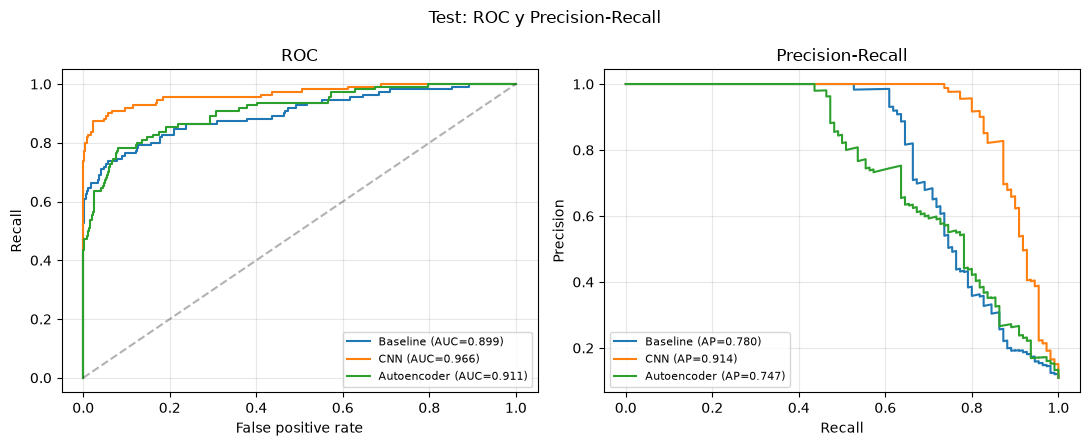

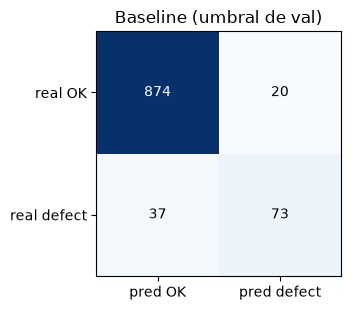

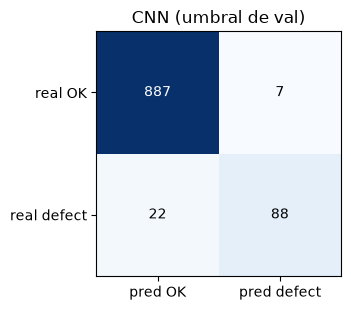

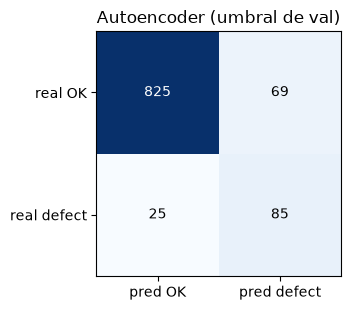

In [7]:
main = ["baseline", "cnn_s42", "ae_s42"]
names = {"baseline": "Baseline", "cnn_s42": "CNN", "ae_s42": "Autoencoder"}
plot_curves({names[k]: (y_te, test_scores[k]) for k in main}, "Test: ROC y Precision-Recall");
for k in main:
    plot_confusion(evaluate(y_te, test_scores[k], REGISTRY[k]["thr"]), f"{names[k]} (umbral de val)")

## 5. Sensibilidad al umbral (solo informativa)
F2 en test en función del umbral. La línea marca el umbral FIJADO en validación. **No se usa para elegir un umbral nuevo.**

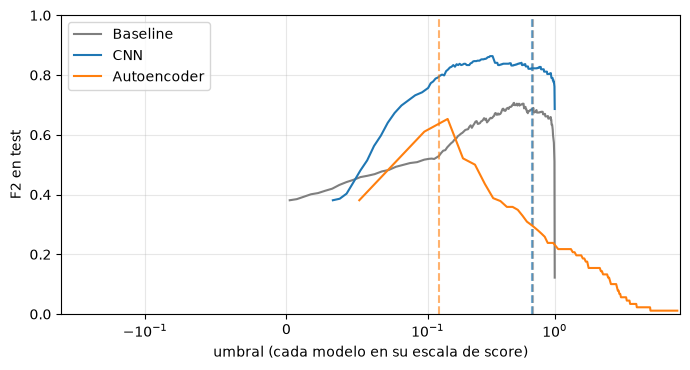

In [8]:
fig, ax = plt.subplots(figsize=(7, 3.8))
for k, col in zip(main, ("tab:gray", "tab:blue", "tab:orange")):
    ts, f2 = final.f2_curve(y_te, test_scores[k])
    ax.plot(ts, f2, color=col, label=names[k]); ax.axvline(REGISTRY[k]["thr"], color=col, ls="--", alpha=.6)
ax.set(xlabel="umbral (cada modelo en su escala de score)", ylabel="F2 en test", ylim=(0, 1)); ax.set_xscale("symlog", linthresh=0.1)
ax.legend(); ax.grid(alpha=.3); plt.tight_layout()

## 6. Diferencias entre modelos (bootstrap pareado de ΔF2 en test)
Cada modelo con su umbral fijo. Si el IC excluye 0, la diferencia no se explica por qué imágenes cayeron en el test.

In [9]:
paired = {}
for b, a in (("cnn_s42", "baseline"), ("ae_s42", "baseline"), ("cnn_s42", "ae_s42")):
    r = paired_bootstrap_diff(y_te, test_scores[a], REGISTRY[a]["thr"], test_scores[b], REGISTRY[b]["thr"])
    paired[f"{b} − {a}"] = r
    print(f"ΔF2 {b} − {a}: {r['diff']:+.3f}  IC95 [{r['ci'][0]:+.3f}, {r['ci'][1]:+.3f}]  P(Δ≤0) = {r['p_not_better']:.3f}")

ΔF2 cnn_s42 − baseline: +0.138  IC95 [+0.082, +0.200]  P(Δ≤0) = 0.000
ΔF2 ae_s42 − baseline: +0.031  IC95 [-0.056, +0.117]  P(Δ≤0) = 0.240
ΔF2 cnn_s42 − ae_s42: +0.107  IC95 [+0.041, +0.179]  P(Δ≤0) = 0.001


## 7. Análisis de errores de la CNN (semilla 42)
¿Qué defectos se escapan? Hipótesis previa: los más chicos (menores a una celda de 32×32 del último mapa, ≈ 1024 px).

In [10]:
s = test_scores["cnn_s42"]; thr = REGISTRY["cnn_s42"]["thr"]; pred = s >= thr
te["cnn_score"] = s; te["cnn_pred"] = pred
fn_df = te[(te.label == 1) & (~te.cnn_pred)].sort_values("defect_px")
fp_df = te[(te.label == 0) & te.cnn_pred].sort_values("cnn_score", ascending=False)
print(f"CNN semilla 42: {len(fn_df)} falsos negativos, {len(fp_df)} falsos positivos")
display(fn_df[["image", "defect_px", "cnn_score"]].round(3))
display(fp_df[["image", "cnn_score"]].head(15).round(3))

bins = [0, 250, 1000, 3000, np.inf]; labels = ["<250 px", "250–1000", "1000–3000", ">3000"]
te["size_bin"] = pd.cut(te.defect_px, bins=bins, labels=labels, right=False)
pos = te.label.to_numpy() == 1
parts = []
for k in main:
    det = test_scores[k] >= REGISTRY[k]["thr"]
    parts.append(te[pos].assign(det=det[pos]).groupby("size_bin", observed=True)["det"].agg(["mean", "sum", "count"]).add_prefix(f"{names[k]} · "))
print("Recall por tamaño de defecto (mean = recall, sum = detectadas, count = total)")
display(pd.concat(parts, axis=1).round(2))

CNN semilla 42: 22 falsos negativos, 7 falsos positivos


,image,defect_px,cnn_score
228,test/20228.png,87,0.180
231,test/20231.png,178,0.553
816,test/20816.png,181,0.060
544,test/20544.png,199,0.063
275,test/20275.png,228,0.095
259,test/20259.png,323,0.133
236,test/20236.png,367,0.065
297,test/20297.png,401,0.589
801,test/20801.png,429,0.096
139,test/20139.png,559,0.160


,image,cnn_score
245,test/20245.png,0.982
651,test/20651.png,0.976
2,test/20002.png,0.931
846,test/20846.png,0.912
580,test/20580.png,0.756
563,test/20563.png,0.754
1000,test/21000.png,0.730


Recall por tamaño de defecto (mean = recall, sum = detectadas, count = total)


,Baseline · mean,Baseline · sum,Baseline · count,CNN · mean,CNN · sum,CNN · count,Autoencoder · mean,Autoencoder · sum,Autoencoder · count
size_bin,,,,,,,,,
<250 px,0.00,0,5,0.00,0,5,0.60,3,5
250–1000,0.21,4,19,0.58,11,19,0.63,12,19
1000–3000,0.72,26,36,0.86,31,36,0.78,28,36
>3000,0.86,43,50,0.92,46,50,0.84,42,50


## 8. Grad-CAM: ¿dónde mira la CNN?
Se mide con la máscara como regla (nunca como entrada): fracción de la energía del mapa que cae dentro del defecto y si el pico del mapa cae adentro. Referencia al azar: fracción de la imagen que ocupa el defecto.

In [11]:
cnn = build_model("resnet18", pretrained=False)
cnn.load_state_dict(torch.load(REGISTRY["cnn_s42"]["ckpt"], map_location="cpu")); cnn.to(device).eval()
ds = InspectDataset(te, DATASET_DIR, get_transforms(False, size))
mean, std = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1), torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

def mask_at(i):
    m = load_mask(DATASET_DIR, te.loc[i, "mask"])
    return np.array(Image.fromarray(m).resize((size[1], size[0]), Image.NEAREST)) > 0

def cam_for(i):
    x, _ = ds[i]
    cam, logit = gradcam(cnn, x.unsqueeze(0).to(device), cnn.layer4[-1])
    return x, cam, logit

res = []
for i in te.index[(te.label == 1) & te.cnn_pred]:
    _, cam, _ = cam_for(i); m = mask_at(i); inside, hit = cam_vs_mask(cam, m)
    res.append({"idx": i, "inside": inside, "hit": hit, "mask_frac": m.mean(), "defect_px": te.loc[i, "defect_px"]})
gr = pd.DataFrame(res)
pointing = {"n_tp": len(gr), "pico_en_defecto": float(gr.hit.mean()), "energia_en_mascara_media": float(gr.inside.mean()), "fraccion_imagen_media": float(gr.mask_frac.mean())}
print(pointing)
print(f"En {gr.hit.mean():.0%} de las defectuosas detectadas el pico del mapa cae dentro del defecto; "
      f"{gr.inside.mean():.0%} de la energía cae en la máscara, que ocupa en promedio {gr.mask_frac.mean():.1%} de la imagen (azar).")

{'n_tp': 88, 'pico_en_defecto': 0.6931818181818182, 'energia_en_mascara_media': 0.2560785773464225, 'fraccion_imagen_media': 0.0360126612696514}
En 69% de las defectuosas detectadas el pico del mapa cae dentro del defecto; 26% de la energía cae en la máscara, que ocupa en promedio 3.6% de la imagen (azar).


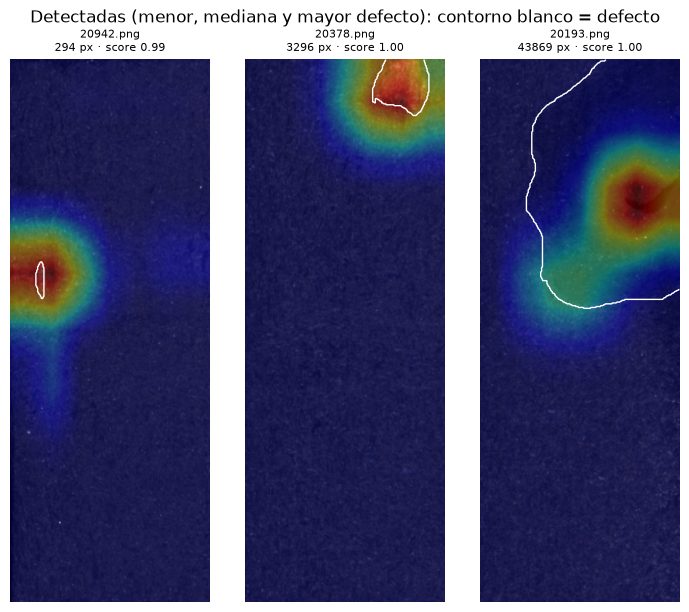

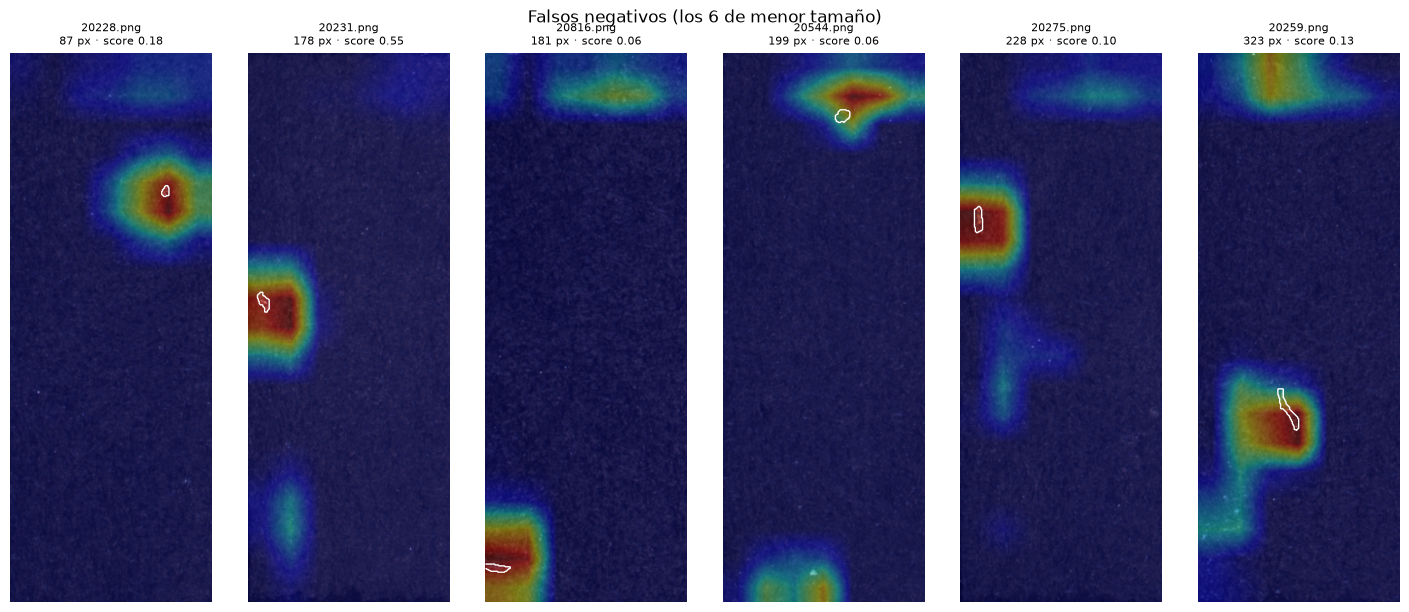

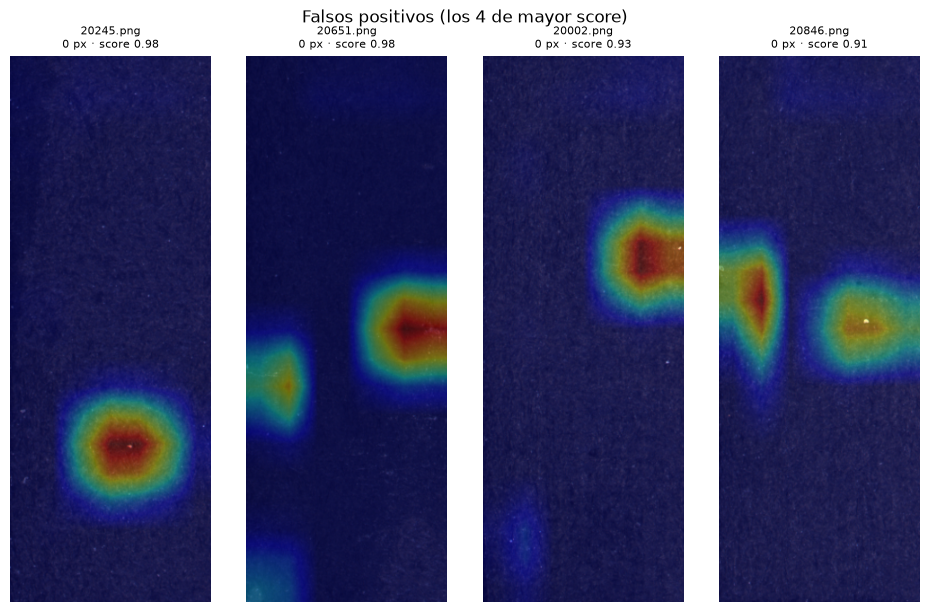

In [12]:
def show(idxs, title):
    if len(idxs) == 0: print("(sin casos)", title); return
    fig, axes = plt.subplots(1, len(idxs), figsize=(2.4 * len(idxs), 6.2), squeeze=False)
    for ax, i in zip(axes[0], idxs):
        x, cam, logit = cam_for(i); img = (x * std + mean).permute(1, 2, 0).clamp(0, 1).numpy()
        ax.imshow(img); ax.imshow(cam, cmap="jet", alpha=0.40)
        if te.loc[i, "label"] == 1: ax.contour(mask_at(i), levels=[0.5], colors="w", linewidths=1)
        ax.set_title(f"{te.loc[i, 'image'].split('/')[-1]}\n{te.loc[i, 'defect_px']} px · score {te.loc[i, 'cnn_score']:.2f}", fontsize=8); ax.axis("off")
    fig.suptitle(title); plt.tight_layout()

tp_df = te[(te.label == 1) & te.cnn_pred].sort_values("defect_px")
pick_tp = list(tp_df.index[[0, len(tp_df) // 2, -1]]) if len(tp_df) >= 3 else list(tp_df.index)
show(pick_tp, "Detectadas (menor, mediana y mayor defecto): contorno blanco = defecto")
show(list(fn_df.index[:6]), "Falsos negativos (los 6 de menor tamaño)")
show(list(fp_df.index[:4]), "Falsos positivos (los 4 de mayor score)")

## 9. Comparación con el paper del dataset
**PENDIENTE (completar con datos reales):** copiar de la tabla del paper de KolektorSDD2 (citado en el plan) las métricas y el protocolo que usan, y anotar en qué difiere el nuestro (otro split de validación, otra métrica principal, resolución). No se completa de memoria.

| Fuente | Método | Métrica del paper | Valor | Protocolo |
|---|---|---|---|---|
| Paper | *(completar)* | *(completar)* | *(completar)* | *(completar)* |
| Nuestro | CNN ResNet18 | AP / F2 | ver sección 2 | split oficial, umbral de val |

## 10. Guardar resultados de test

In [13]:
out = {"evaluado": pd.Timestamp.now().isoformat(), "protocolo": "D-045", "n_test": len(te), "n_defect": int(te.label.sum()),
       "tabla": tab.to_dict("records"),
       "media_std": {fam: {c: {"mean": float(g[c].mean()), "std": float(g[c].std(ddof=1)) if len(g) > 1 else None} for c in cols}
                     for fam, g in tab.groupby("familia")},
       "ic95_semilla42": ci_rows, "pareado": paired, "grad_cam": pointing,
       "recall_por_tamano": pd.concat(parts, axis=1).reset_index().astype(str).to_dict("records")}
json.dump(out, open(RESULTS_DIR / "test_results.json", "w"), indent=2, default=float)
print("Guardado:", RESULTS_DIR / "test_results.json")

Guardado: /Users/ipejinakis/Documents/Ingenieria-UCA/Inteligencia Artificial/InspectIA/repo/results/test_results.json


## Registro
Pegar acá (o en `docs/RESULTADOS.md`) los números de test, qué cambió respecto de validación y las conclusiones. **No se reentrena ni se cambia ningún umbral a partir de lo que se vea en esta notebook.**